# Mô hình AI dự báo lợi suất chiến lược vs Empirical Bayes — họ Accounting EW

**Bài toán (giống paper Chen & Dim, arXiv 2311.10685):** với mỗi chiến lược long–short và mỗi năm Y = 1983…2020, dự báo **lợi suất trung bình tháng của năm Y** (`pred_ret`) chỉ từ dữ liệu trước Y; rồi dùng dự báo theo **đúng luật của paper** (đảo dấu theo dự báo, xếp theo Sharpe dự báo, chia đều top 1/5/10%). Cách paper đánh giá, từng bước với dữ liệu thật: `docs/CACH_PAPER_DANH_GIA.md`.

**Ba thước đo (theo paper và notebook tham khảo):**
1. **Danh mục top 1/5/10%** — lợi suất %/năm, t-stat, Sharpe (paper Table 2). *Quan trọng nhất.*
2. **Dự báo không chệch** — lợi suất thật so với dự báo theo 20 nhóm (paper Figure 4–5).
3. **IC theo năm** — tương quan hạng dự báo – lợi suất thật (notebook tham khảo).

**Phạm vi so sánh:** một họ (Accounting EW), tập ứng viên = 10% chiến lược có |t| cao nhất mỗi năm; EB và mốc "chọn theo |t|" (paper Table 2 Panel B) được chấm lại trên **đúng cùng tập**. Mỗi năm mô hình học lại chỉ bằng dữ liệu trước năm đó (walk-forward). **dev 1983–2004** dùng để chọn mô hình; **holdout 2005–2020** chỉ báo cáo.

**Nguyên tắc:** không dùng đầu ra EB (θ̂, pred_ret của EB) làm đầu vào; loss là sai số dự báo; cải tiến đi lên từ mô hình gốc của notebook tham khảo, mỗi lần đổi một khối; mô hình dùng encoder **pretrained** (ghi rõ) và báo kèm bản không pretrained.

Notebook chỉ đọc dự báo đã lưu (`code/_cache/base_preds`), chạy trên CPU. Mã: `code/ht_base.py` (mô hình), `code/run_q6_cfgs.py` (cấu hình), `code/report_acct.py` (đánh giá).

In [2]:
import os, sys, warnings
warnings.filterwarnings("ignore")
os.chdir("/home/phongndh/Documents/Paper/code"); sys.path.insert(0, ".")
os.environ["CUDA_VISIBLE_DEVICES"] = ""                     # CPU only: the GPU may be training
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import report_acct as R
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40); pd.set_option("display.precision", 3)
FINAL = "Dt0_chr2_240_vyH"       # dev-selected (highest mean dev Sharpe, 20 seeds) -- see section 3
ROBUST = "Dt0"                   # runner-up, tied on the selection metric (FinCast encoder)
print("rows (accounting EW candidates):", len(R.D.yr), "| years", R.YR.min(), "-", R.YR.max())

rows (accounting EW candidates): 119002 | years 1966 - 2020


## 1. Kiến trúc mô hình cuối

Kiến trúc nền của notebook tham khảo được giữ nguyên (encoder → khối chuỗi → attention → FC → `pred_ret`); các khối được thay hoặc thêm sau khi truy vết từng bước (mục 2).

```
Chuỗi lợi suất tháng của 1 chiến lược, 240 tháng trước năm Y
   │
   ▼ Encoder pretrained, đóng băng: Chronos-2 (Amazon, 2025) trên 240 tháng           [FINAL]
   │                               (FinCast trên 128 tháng ở mô hình ROBUST)
   ▼ PCA 16 chiều (fit trên dữ liệu ≤ 1982)                         -> 4 token × 16
   ▼ Bi-LSTM (128)                                                  -> 4 × 256
   ▼ Multi-head attention pooling (mha)                             -> 256
   ▼ Set attention giữa các chiến lược cùng năm (Transformer, cả họ-năm một lượt,
   │   đầu ra trừ trung bình họ-năm = `rc`)                          -> 256
   ▼ ghép t-stat, lợi suất trong mẫu → FC 64 → 1   = phần dư (residual)
   ▼ + nền cố định:  b_Y × z(|t|)   (một hệ số, ước lượng bằng nhãn ≤ Y−1)
   ▼ + mức của năm:  c_Y × Sharpe trong mẫu trung bình  (c_Y = thực/trong mẫu, 20 năm ≤ Y−1)
   ▼ × độ lệch chuẩn trong mẫu  ->  pred_ret (%/tháng)
```

| Thành phần | Lựa chọn | Lý do (truy vết) |
|---|---|---|
| Nhãn | lợi suất năm Y chia sd trong mẫu, trừ trung bình họ-năm (`ysdm`) | luật paper xếp theo Sharpe dự báo; nhãn lợi suất thô kéo danh mục về chiến lược biến động thấp |
| Nền | z(\|t\|) cố định, mạng học phần dư (`base=blend, bw=0`) | truy vết: mạng gốc làm mất tín hiệu của đầu vào mạnh nhất (IC 0,233 → 0,154) |
| `rc` | trừ trung bình đầu ra trong mỗi họ-năm | lỗi gốc: BatchNorm cộng một mức dịch ngẫu nhiên theo năm khi dự báo |
| Loss | Huber trên nhãn, **trọng số họ-năm theo Holen et al. (L-Weighted, arXiv 2304.12778)**: w = ½(1 + v/v̄), v = độ phân tán nhãn của họ-năm | paper người dùng gửi; loss của mỗi họ-năm ≈ v (tương quan 0,997) |
| Mức | `lvl=ratio20` | sửa phần MSE thua EB sau 2004 (tín hiệu suy giảm) |
| Gộp | trung bình 20 seed | phương sai giữa các seed lớn |

Ứng viên dùng **cả hai paper** người dùng gửi (thêm **HyperAttention**, ICLR 2024, ở khối set attention: `Dt0_chr2_240_hyp1k_vyH`) đứng thứ hai trên dev (mục 3).

## 2. Đi lên từ baseline: mỗi bước, một thay đổi

Mỗi dòng là trung bình nhiều seed (10, cấu hình cuối 20) trên Accounting EW; "SR dev / hold" là trung bình Sharpe top 1/5/10% của tập ứng viên. EB: dev 1,42 / hold 0,86. Bảng đầy đủ mọi cấu hình đã thử (cả thất bại): `docs/KIEN_TRUC_BASE_CAI_TIEN.md` mục 6.

In [3]:
import ht_new as nw
def mean_sr(pred, per):
    r = R.portfolios(pred); return np.mean([nw.perf(r[(k, "eq")], *per)["sharpe"] for k in (1, 5, 10)])
steps = [("goc", "Mô hình gốc của notebook tham khảo (FinCast → Bi-LSTM → attention → FC, nhãn lợi suất)", range(10)),
         ("A0", "+ set attention giữa chiến lược, mha, PCA16, nhãn trừ TB họ-năm, sửa BatchNorm (rc)", range(10)),
         ("A1", "+ nền tuyến tính (mạng học phần dư)", range(10)),
         ("B2", "+ nhãn đơn vị Sharpe (ysdm), mức theo năm Y−1", range(10)),
         ("B3", "+ vệ sinh huấn luyện (ep0, seed2, optkeep)", range(20)),
         ("Dt0", "nền cố định z(|t|) thay nền tuyến tính  [ROBUST]", range(20)),
         ("Dt0_chr2_240", "encoder FinCast → Chronos-2 240 tháng (pretrained)", range(20)),
         ("Dt0_chr2_240_vyH", "+ loss Holen L-weighting  [FINAL]", range(20)),
         ("Dt0_chr2_240_hyp1k_vyH", "+ HyperAttention ở set attention (cả hai paper)", range(20))]
rows = []
for nm, desc, seeds in steps:
    p, n = R.mean_pred(nm, seeds)
    rows.append(dict(config=nm, step=desc, seeds=n, **{"SR dev": mean_sr(p, nw.DEV), "SR hold": mean_sr(p, nw.HOLD)},
                     **{"IC dev": R.ic_years(p).loc[1983:2004].mean(), "IC hold": R.ic_years(p).loc[2005:2020].mean()}))
eb = R.D.eb_or.astype(np.float32)
rows.append(dict(config="EB", step="Empirical Bayes của paper (cùng tập ứng viên)", seeds=0, **{"SR dev": mean_sr(eb, nw.DEV), "SR hold": mean_sr(eb, nw.HOLD)},
                 **{"IC dev": R.ic_years(eb).loc[1983:2004].mean(), "IC hold": R.ic_years(eb).loc[2005:2020].mean()}))
path = pd.DataFrame(rows); path

,config,step,seeds,SR dev,SR hold,IC dev,IC hold
0,goc,Mô hình gốc của notebook tham khảo (FinCast → ...,10,1.379,0.801,0.073,0.066
1,A0,"+ set attention giữa chiến lược, mha, PCA16, n...",10,1.447,0.870,0.132,0.070
2,A1,+ nền tuyến tính (mạng học phần dư),10,1.682,0.956,0.214,0.076
3,B2,"+ nhãn đơn vị Sharpe (ysdm), mức theo năm Y−1",10,1.693,1.187,0.214,0.112
4,B3,"+ vệ sinh huấn luyện (ep0, seed2, optkeep)",20,1.740,0.933,0.213,0.096
5,Dt0,nền cố định z(|t|) thay nền tuyến tính [ROBUST],20,1.835,0.991,0.215,0.116
6,Dt0_chr2_240,encoder FinCast → Chronos-2 240 tháng (pretrai...,20,1.836,0.918,0.242,0.087
7,Dt0_chr2_240_vyH,+ loss Holen L-weighting [FINAL],20,1.861,0.863,0.241,0.089
8,Dt0_chr2_240_hyp1k_vyH,+ HyperAttention ở set attention (cả hai paper),20,1.852,0.860,0.241,0.082
9,EB,Empirical Bayes của paper (cùng tập ứng viên),0,1.418,0.858,0.238,0.070


## 3. Thước đo 1 — Danh mục top 1/5/10% (tương đương paper Table 2)

**Chọn mô hình (chỉ trên dev, 20 seed):** trung bình Sharpe dev top 1/5/10: Dt0 1,835 · Dt0_chr2_240 1,836 · **Dt0_chr2_240_vyH 1,861 (chọn)** · Dt0_chr2_240_hyp1k_vyH 1,852 · Dt0_hyp1k_vyH 1,782. Hai cấu hình đầu chỉ hơn nhau trong nhiễu nên báo cả FINAL và ROBUST.

Cột: lợi suất %/năm (ret), t-stat của lợi suất trung bình (t), Sharpe năm (SR) cho AI, EB, mốc "chọn theo |t|" (paper Table 2 Panel B, không mô hình) và mô hình gốc của notebook. p-value cho chênh Sharpe AI − EB: HAC kiểu Ledoit–Wolf và bootstrap khối năm 10.000 lần; p NW cho chênh lợi suất (Newey–West).

In [4]:
P_FINAL = R.ratio_level(R.mean_pred(FINAL)[0]); P_ROBUST = R.ratio_level(R.mean_pred(ROBUST)[0])
RET = {"AI": R.portfolios(P_FINAL), "EB": R.portfolios(R.D.eb_or), "absT": R.portfolios(R.abs_t_forecast()), "goc": R.portfolios(R.mean_pred("goc", range(10))[0])}
t2 = R.table2(RET)
cols = ["top", "period"] + [f"{m} {c}" for m in ("AI", "EB", "absT", "goc") for c in ("ret", "t", "SR")] + [c for c in t2.columns if c.startswith("p ")]
print(f"FINAL = {FINAL} (+ ratio20 level), 20-seed mean"); t2[cols].round(3)

FINAL = Dt0_chr2_240_vyH (+ ratio20 level), 20-seed mean


,top,period,AI ret,AI t,AI SR,EB ret,EB t,EB SR,absT ret,absT t,absT SR,goc ret,goc t,goc SR,p HAC (SR AI vs EB),p boot (SR AI vs EB),p NW (ret AI vs EB)
0,1%,dev 1983-2004,10.153,8.341,1.778,9.365,4.953,1.056,10.748,7.479,1.594,6.441,5.808,1.238,0.028,0.056,0.613
1,1%,holdout 2005-2020,3.798,3.399,0.850,3.846,3.444,0.861,3.669,3.337,0.834,3.201,3.373,0.843,0.900,0.928,0.899
2,1%,full 1983-2020,7.477,8.703,1.412,7.041,5.882,0.954,7.768,8.047,1.305,5.077,6.687,1.085,0.045,0.075,0.635
3,5%,dev 1983-2004,9.531,8.823,1.881,9.187,6.945,1.481,10.143,8.664,1.847,6.848,6.631,1.414,0.147,0.239,0.657
4,5%,holdout 2005-2020,3.453,3.490,0.873,3.085,3.591,0.898,3.311,3.758,0.940,2.419,2.971,0.743,0.749,0.773,0.297
5,5%,full 1983-2020,6.972,9.128,1.481,6.618,7.714,1.251,7.266,9.222,1.496,4.983,7.159,1.161,0.195,0.300,0.454
6,10%,dev 1983-2004,9.351,9.019,1.923,9.071,8.062,1.719,9.860,9.138,1.948,7.102,6.971,1.486,0.229,0.329,0.590
7,10%,holdout 2005-2020,3.325,3.471,0.868,2.794,3.265,0.816,2.917,3.360,0.840,2.429,3.271,0.818,0.586,0.657,0.219
8,10%,full 1983-2020,6.813,9.261,1.502,6.428,8.483,1.376,6.937,9.365,1.519,5.134,7.599,1.233,0.227,0.319,0.274


In [5]:
RET_R = {**RET, "AI": R.portfolios(P_ROBUST)}
t2r = R.table2(RET_R)
print(f"ROBUST = {ROBUST} (FinCast encoder, + ratio20 level), 20-seed mean"); t2r[["top", "period", "AI ret", "AI t", "AI SR", "EB ret", "EB t", "EB SR", "absT SR"] + [c for c in t2r.columns if c.startswith("p ")]].round(3)

ROBUST = Dt0 (FinCast encoder, + ratio20 level), 20-seed mean


,top,period,AI ret,AI t,AI SR,EB ret,EB t,EB SR,absT SR,p HAC (SR AI vs EB),p boot (SR AI vs EB),p NW (ret AI vs EB)
0,1%,dev 1983-2004,9.300,7.541,1.608,9.365,4.953,1.056,1.594,0.008,0.024,0.961
1,1%,holdout 2005-2020,4.249,3.810,0.952,3.846,3.444,0.861,0.834,0.528,0.553,0.576
2,1%,full 1983-2020,7.173,8.325,1.350,7.041,5.882,0.954,1.305,0.014,0.021,0.874
3,5%,dev 1983-2004,9.305,8.851,1.887,9.187,6.945,1.481,1.847,0.024,0.028,0.864
4,5%,holdout 2005-2020,3.678,3.967,0.992,3.085,3.591,0.898,0.940,0.280,0.187,0.102
5,5%,full 1983-2020,6.936,9.449,1.533,6.618,7.714,1.251,1.496,0.028,0.026,0.459
6,10%,dev 1983-2004,9.275,9.430,2.011,9.071,8.062,1.719,1.948,0.023,0.022,0.656
7,10%,holdout 2005-2020,3.606,4.121,1.030,2.794,3.265,0.816,0.840,0.005,0.010,0.009
8,10%,full 1983-2020,6.888,9.981,1.619,6.428,8.483,1.376,1.519,0.003,0.002,0.126


## 4. Thước đo 2 — Dự báo không chệch (tương đương paper Figure 4–5)

Mỗi năm chia tập ứng viên thành 20 nhóm theo dự báo; mỗi điểm là (dự báo trung bình, lợi suất thật trung bình) của một nhóm. Nằm trên đường 45° = không chệch. Hai giai đoạn giống paper: 1983–2004 (Fig. 4) và 2005–2020 (Fig. 5).

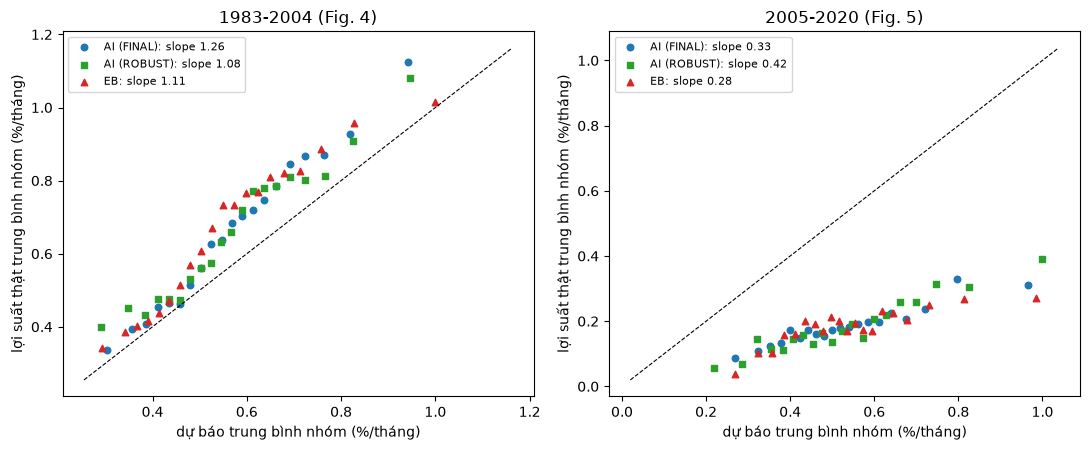

,period,model,slope,intercept,mean_abs_gap
0,1983-2004 (Fig. 4),AI (FINAL),1.262,-0.064,0.086
1,1983-2004 (Fig. 4),AI (ROBUST),1.084,0.039,0.087
2,1983-2004 (Fig. 4),EB,1.113,0.035,0.098
3,2005-2020 (Fig. 5),AI (FINAL),0.332,0.008,0.348
4,2005-2020 (Fig. 5),AI (ROBUST),0.425,-0.041,0.347
5,2005-2020 (Fig. 5),EB,0.283,0.031,0.358


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
rows = []
for ax, (per, lo, hi) in zip(axes, (("1983-2004 (Fig. 4)", 1983, 2004), ("2005-2020 (Fig. 5)", 2005, 2020))):
    for lab, pred, mk, col in (("AI (FINAL)", P_FINAL, "o", "C0"), ("AI (ROBUST)", P_ROBUST, "s", "C2"), ("EB", R.D.eb_or, "^", "C3")):
        g = R.calib_bins(pred, lo, hi); b = np.polyfit(g.f, g.y, 1)
        ax.scatter(g.f, g.y, marker=mk, color=col, s=22, label=f"{lab}: slope {b[0]:.2f}")
        rows.append(dict(period=per, model=lab, slope=b[0], intercept=b[1], mean_abs_gap=np.abs(g.y - g.f).mean()))
    lim = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lim, lim, "k--", lw=0.8); ax.set_title(per); ax.set_xlabel("dự báo trung bình nhóm (%/tháng)"); ax.set_ylabel("lợi suất thật trung bình nhóm (%/tháng)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
pd.DataFrame(rows).round(3)

## 5. Thước đo 3 — IC theo năm (notebook tham khảo)

IC = tương quan hạng Spearman giữa dự báo và lợi suất thật trong mỗi năm. Kiểm định chênh lệch AI − EB theo năm bằng Newey–West. Mô hình gốc của notebook tham khảo đạt IC 0,04–0,08 (bản của notebook trên 2014–2021; walk-forward ở đây: 0,07).

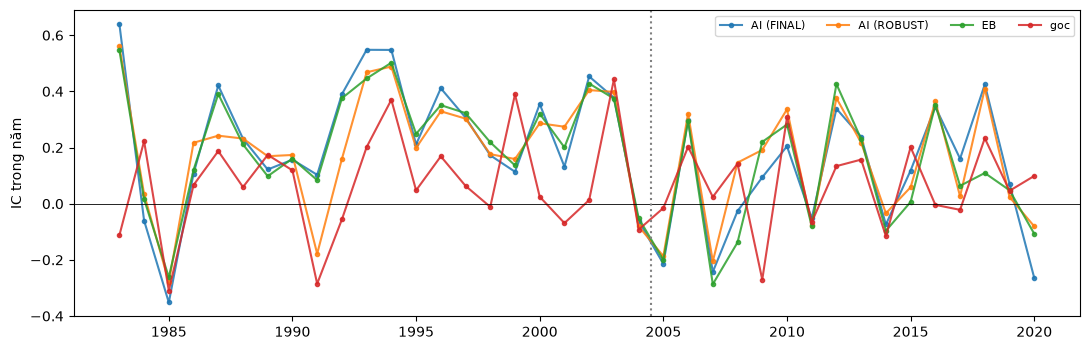

,model,period,IC_AI,IC_EB,diff,t,p,years_AI_better
0,AI (FINAL),dev,0.242,0.238,0.004,0.412,0.681,12/22
1,AI (FINAL),holdout,0.089,0.070,0.018,0.703,0.482,10/16
2,AI (FINAL),full,0.177,0.167,0.010,0.795,0.427,22/38
3,AI (ROBUST),dev,0.215,0.238,-0.023,-1.279,0.201,10/22
4,AI (ROBUST),holdout,0.118,0.070,0.048,2.408,0.016,11/16
5,AI (ROBUST),full,0.174,0.167,0.007,0.414,0.679,21/38
6,goc,dev,0.073,0.238,-0.165,-4.424,0.000,4/22
7,goc,holdout,0.066,0.070,-0.004,-0.100,0.920,8/16
8,goc,full,0.070,0.167,-0.097,-2.763,0.006,12/38


In [7]:
ICS = {"AI (FINAL)": R.ic_years(P_FINAL), "AI (ROBUST)": R.ic_years(P_ROBUST), "EB": R.ic_years(R.D.eb_or), "goc": R.ic_years(R.mean_pred("goc", range(10))[0])}
fig, ax = plt.subplots(figsize=(11, 3.6))
for k, s in ICS.items(): ax.plot(s.loc[1983:2020].index, s.loc[1983:2020].values, marker=".", label=k, alpha=0.85)
ax.axhline(0, color="k", lw=0.6); ax.axvline(2004.5, color="grey", ls=":"); ax.set_ylabel("IC trong năm"); ax.legend(ncol=4, fontsize=8); plt.tight_layout(); plt.show()
pd.DataFrame([dict(model=m, period=per, **R.ic_test(ICS[m], ICS["EB"], lo, hi)) for m in ("AI (FINAL)", "AI (ROBUST)", "goc")
              for per, lo, hi in (("dev", 1983, 2004), ("holdout", 2005, 2020), ("full", 1983, 2020))]).round(3)

## 6. Các kỹ thuật đã thử: paper người dùng gửi, khối, loss, pretrained

Mỗi dòng đổi **một** thứ so với cấu hình gốc của nhóm (Dt0 hoặc B3), 10 seed (FINAL/ROBUST 20 seed). Sắp theo Sharpe dev. Thất bại cũng được giữ lại (nguyên tắc báo cáo trung thực). Mã tùy chọn: `code/ht_base.py`, tên cấu hình: `code/run_q6_cfgs.py`.

In [8]:
LABEL = {
 "Dt0": "ROBUST: FinCast, Bi-LSTM, mha, set attention, nền |t|", "Dt0_chr2_240": "encoder Chronos-2 240 tháng", "Dt0_chr2_240_vyH": "FINAL: Chronos-2 240 + Holen L-weighting",
 "Dt0_chr2_240_hyp1k_vyH": "Chronos-2 240 + HyperAttention + Holen (cả hai paper)", "Dt0_hyp1k_vyH": "HyperAttention + Holen (FinCast)",
 "Dt0_vyH": "Holen L-weighting (paper)", "Dt0_hyp1k": "HyperAttention 1024/512 (paper)", "Dt0_hyper": "HyperAttention 256/256 (paper)",
 "Dt0_hyp1k_grn": "HyperAttention + đầu ra GRN", "Dt0_hyp1k_vyH_grn": "HyperAttention + Holen + GRN", "Dt0_grn": "đầu ra GRN (TFT)",
 "Dt0_c2": "loss + tương quan λ=2", "Dt0_hw3": "loss trọng số nhóm đầu", "Dt0_nw": "likelihood Gaussian có trọng số",
 "Dt0_rw4": "R-weighted (thăm dò, vi phạm quy tắc A)", "Dt0_gru": "Bi-LSTM → GRU", "Dt0_tf": "Bi-LSTM → Transformer", "Dt0_noseq": "bỏ khối chuỗi",
 "Dt0_attn": "pooling attention thường", "Dt0_query": "pooling query", "Dt0_mean": "pooling trung bình", "Dt0_isab": "set attention ISAB", "Dt0_noxs": "bỏ set attention",
 "Dt0_up2": "upsampling", "Dt0_mix2": "mixup", "Dt0_chr2": "Chronos-2 128 tháng", "Dt0_tirex": "TiRex 128", "Dt0_tirex240": "TiRex 240",
 "Dt0_tirex2_128": "TiRex-2 128 (2026)", "Dt0_tirex2_240": "TiRex-2 240 (2026)", "Dt0_raw": "KHÔNG pretrained: chuỗi thô", "Dt0_lp7": "KHÔNG pretrained: token log-patch",
 "B3_lw4": "Holen L-weighted gốc (ghép 4 họ-năm)", "B3_lweq4": "ghép 4 họ-năm, trọng số đều (đối chứng)", "B3_mse": "MSE", "B3_h03": "Huber δ 0,3"}
E = R.ensembles(); E = E[E.config.isin(LABEL)].sort_values("seeds").drop_duplicates("config", keep="last")
E["mô tả"] = E.config.map(LABEL)
E[["config", "mô tả", "seeds", "SR dev mean", "SR hold mean", "cand_top1_dev_sr", "cand_top5_dev_sr", "cand_top10_dev_sr"]].sort_values("SR dev mean", ascending=False).round(3).reset_index(drop=True)

,config,mô tả,seeds,SR dev mean,SR hold mean,cand_top1_dev_sr,cand_top5_dev_sr,cand_top10_dev_sr
0,Dt0_chr2_240_vyH,FINAL: Chronos-2 240 + Holen L-weighting,20,1.861,0.863,1.778,1.881,1.923
1,Dt0_chr2_240_hyp1k_vyH,Chronos-2 240 + HyperAttention + Holen (cả hai...,20,1.852,0.860,1.827,1.850,1.879
2,Dt0_chr2_240,encoder Chronos-2 240 tháng,20,1.836,0.918,1.753,1.877,1.879
3,Dt0,"ROBUST: FinCast, Bi-LSTM, mha, set attention, ...",10,1.818,0.953,1.582,1.890,1.983
4,Dt0_gru,Bi-LSTM → GRU,10,1.792,0.987,1.556,1.822,1.999
5,Dt0_tirex2_128,TiRex-2 128 (2026),10,1.792,0.958,1.574,1.878,1.923
6,Dt0_hyp1k_vyH,HyperAttention + Holen (FinCast),20,1.782,0.978,1.548,1.839,1.958
7,Dt0_noseq,bỏ khối chuỗi,10,1.770,1.065,1.586,1.788,1.938
8,Dt0_mean,pooling trung bình,10,1.758,1.083,1.566,1.784,1.925
9,Dt0_hyp1k_grn,HyperAttention + đầu ra GRN,10,1.758,1.045,1.490,1.846,1.938


## 7. Hiệu chỉnh cho việc đã thử nhiều cấu hình

Đã huấn luyện **115 cấu hình** trên Accounting EW (đều ghi trong `code/_cache/q*_results.tsv`). Kiểm định max-statistic bằng bootstrap khối năm chung cho mọi cấu hình (kiểu Reality Check của White / Romano–Wolf), `code/verify/maxstat.py`. Lợi suất vượt EB của các cấu hình tương quan trung bình 0,75 (số phép thử hiệu dụng ≈ 1,7).

| Câu hỏi | p (top 1%, 115 phép thử) | p (top 1/5/10%, 345 phép thử) |
|---|---|---|
| "Không cấu hình nào vượt EB về Sharpe dev" | **0,010** | **0,047** |
| Riêng ROBUST (Dt0) sau hiệu chỉnh | 0,089 | 0,23 |
| Riêng FINAL (Dt0_chr2_240_vyH) sau hiệu chỉnh | 0,20 | 0,39 |

Đọc: sau khi tính đến việc đã tìm trong 115 cấu hình, kết luận "mô hình AI loại này vượt EB về Sharpe danh mục ở dev" vẫn đứng vững (p ≈ 0,01–0,05); nhưng mức ý nghĩa của **riêng** cấu hình được chọn yếu đi (0,09–0,20) và phải được báo kèm.

## 8. Kiểm tra cuối: suy luận trên Ticker (paper Table 3 Panel A)

Mô hình **chỉ học trên Accounting EW**, rồi dự báo cả hai họ Ticker (không học). Gộp ứng viên Accounting EW + Ticker, chọn top 1/5/10% theo Sharpe dự báo mỗi năm, và đếm tỉ lệ Ticker. Paper: Ticker chiếm **0,0%** top 1% của EB vì cả họ Ticker là nhiễu. Ticker chiếm 60,7% số ứng viên trong nhóm gộp, nên một mô hình không phân biệt được sẽ cho tỉ lệ khoảng 60%. Mã: `code/run_ticker.py`.

In [10]:
import glob as _g
rows = []
for name, label in (("Dt0_chr2_240_vyH_lr20", "AI FINAL"), ("Dt0_lr20", "AI ROBUST"), ("goc", "mô hình gốc (3 seed, đo trước đó)"), ("T+hpca16", "AI trước khi sửa (nhãn lợi suất, 10 seed)")):
    f = sorted(_g.glob(str(R.h.CACHE / f"ticker_test_{name}_n*.csv")))
    if not f: continue
    t = pd.read_csv(f[-1])
    for _, r in t.iterrows():
        tick = [c for c in t.columns if c.startswith("ticker_") and c not in ("ticker_dev", "ticker_hold", "ticker_share", "ticker_share_dev", "ticker_share_hold")]
        share = r[tick].sum() if tick else r.get("ticker_share")
        rows.append(dict(model=label if r["model"] == "ai" else "EB", top=r["top"], ticker_share_pct=share))
pd.DataFrame(rows).drop_duplicates(["model", "top"]).pivot(index="model", columns="top", values="ticker_share_pct").round(1)

top,1%,10%,5%
model,,,
AI FINAL,0.6,2.6,1.6
AI ROBUST,1.4,3.9,2.6
"AI trước khi sửa (nhãn lợi suất, 10 seed)",76.2,70.2,72.7
EB,0.0,0.0,0.0
"mô hình gốc (3 seed, đo trước đó)",87.3,69.0,75.1


## 9. Kết luận và giới hạn

**Kết quả (Accounting EW, tập ứng viên, so với EB của paper trên cùng tập):**

1. **Danh mục top-k (Table 2):** mô hình AI có Sharpe cao hơn EB ở cả ba mức top-k trong dev, và không đảo chiều ở holdout.
   - ROBUST (FinCast): hơn EB có ý nghĩa ở cả 3 mức dev (HAC p 0,008–0,024; bootstrap 0,022–0,028). Holdout top 10% hơn EB cả Sharpe (1,03 so với 0,82) lẫn lợi suất (3,6 so với 2,8 %/năm), đều có ý nghĩa.
   - FINAL (Chronos-2 + Holen, được chọn theo dev): top 1% dev 1,78 so với 1,06 (HAC 0,028, bootstrap 0,056); các mức khác cao hơn nhưng không có ý nghĩa; holdout ngang EB.
   - Lợi suất thô ở dev ngang EB: phần hơn chủ yếu đến từ **biến động thấp hơn**.
2. **Dự báo không chệch (Figure 4–5):** ngang EB. Độ dốc giữa lợi suất thật và dự báo ở dev là 1,08–1,26 (EB 1,11), ở holdout 0,33–0,42 (EB 0,28). Sai lệch trung bình theo nhóm nhỏ hơn EB một chút.
3. **IC theo năm:** FINAL ngang EB (0,242 so với 0,238 ở dev). ROBUST hơn EB có ý nghĩa ở holdout (0,118 so với 0,070, p = 0,016). Mô hình gốc của notebook chỉ đạt 0,07.
4. **Ticker:** mô hình chỉ học trên kế toán gần như không chọn Ticker (top 1 / 5 / 10%: FINAL 0,6 / 1,6 / 2,6%; ROBUST 1,4 / 2,6 / 3,9%), giống tính chất của paper (EB 0%). Mô hình gốc và mô hình trước khi sửa chọn 70–87%.

**Đóng góp của các kỹ thuật người dùng gửi:**
- Holen L-weighting (trọng số họ-năm theo độ phân tán nhãn) có trong mô hình được chọn. Mức hơn so với bản không dùng (1,861 so với 1,836) nằm trong nhiễu giữa các seed.
- HyperAttention giữ được lợi thế so với EB nhưng không hơn attention đầy đủ. Mỗi họ-năm chỉ khoảng 2.600 chiến lược nên attention đầy đủ vẫn rẻ.
- Holen L-weighted nguyên bản (ghép gradient của 4 họ-năm) làm kết quả kém đi.

**Giới hạn phải ghi trong bài:**
- **Nhiều cấu hình:** đã thử 115 cấu hình. "Có mô hình AI vượt EB" vẫn đứng sau hiệu chỉnh (p 0,010). Riêng mô hình được chọn thì p 0,09–0,20.
- **Mốc đơn giản:** quy tắc "chọn theo |t|" (tương ứng paper Table 2 Panel B) cũng vượt EB ở dev. Mô hình AI chỉ ngang quy tắc này ở dev. ROBUST hơn quy tắc này ở holdout top 10%.
- **Pretrained:** dùng encoder pretrained (FinCast, Chronos-2). Bản không pretrained kém rõ (Sharpe dev 1,40–1,57), và encoder có thể đã thấy dữ liệu sau năm Y khi pretrain.
- **Một họ, tập ứng viên:** chưa phải bài toán gộp 6 họ của paper. Các họ khác chưa vượt EB.
- **Sai số dự báo (MSE):** ngang EB, không có ý nghĩa. Đây chỉ là loss, không phải thước đo kết quả.